In [1]:
import os, sys
sys.path.append(os.path.abspath(os.path.join('..')))

In [2]:
import numpy as np
import pandas as pd
import math
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sea

In [3]:
from sklearn.model_selection import train_test_split
from src.models import SimpleLinearRegression, MultipleLinearRegression
from src.data import load_csv

In [4]:
class MultipleLinearRegression:
    def __init__(self):
        self.beta_hat = None
        self.intercept_ = None
        self.coef_ = None
        self.loss_history_ = None
        self.lr_ = None
        self.lr_limit_ = None
        self.n_iter_ = None


    def _add_intercept(self, X):
        X = np.asarray(X, dtype=float)

        return np.c_[np.ones(X.shape[0]), X]

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        X_design = self._add_intercept(X)

        XTX = X_design.T @ X_design

        XTy = X_design.T @ y

        cond_number = np.linalg.cond(XTX)
        print(f"Condition Number: {cond_number}")

        self.beta_hat = np.linalg.solve(XTX, XTy)
        self.intercept_ = self.beta_hat[0]
        self.coef_ = self.beta_hat[1:]

        return self

    def fit_gd(self, X, y, lr_=None, epochs=1000, tolerance=1e-3):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        X = self._add_intercept(X)
        XTX = X.T @ X
        n = X.shape[0]

        H = (2/n) * XTX
        eigen_values = np.linalg.eigvalsh(H)


        max_ev = np.max(eigen_values)
        cond_number = max_ev / np.min(eigen_values)
        print(f"Condition Number: {cond_number}")

        self.lr_limit_ = 2 / max_ev
        self.lr_ = lr_ if lr_ is not None else 1 / max_ev
        print(f"Learning Rate: {self.lr_} Limit: {self.lr_limit_}, Max Eigen value: {max_ev}")

        if self.lr_ >= self.lr_limit_:
            print("Warning: lr_ is at or above the stability limit, expect divergence")

        self.beta_hat = np.zeros(X.shape[1]) # jitne columns h, utne B aur ek intercept ke liye pehla wala !!
        
        self.loss_history_ = []
        self.n_iter_ = epochs
        for epoch in range(epochs):
            y_pred = X @ self.beta_hat
            gradient = -(2/n) * X.T @(y - y_pred)
            self.beta_hat = self.beta_hat - self.lr_ * gradient
            loss = np.mean((y - y_pred) ** 2)
            self.loss_history_.append(loss)
            self.n_iter_ = epoch + 1


            if not np.isfinite(loss):
                print("Diverged at epoch:", epoch)
                break

            if epoch > 0 and abs(self.loss_history_[-2] - self.loss_history_[-1]) < tolerance:
                print("Converged at epoch: ", epoch)
                break

        self.intercept_ = self.beta_hat[0] ## B0
        self.coef_ = self.beta_hat[1:] ## B1 to Bn
        return self

    def predict(self, X):
        if self.beta_hat is None:
            raise ValueError("Model is not fitted yet! Please Call .fit() first")
        X = np.asarray(X, dtype=float)
        X_test_design = self._add_intercept(X)
        return X_test_design @ self.beta_hat

    def residual(self, X, y):
        y = np.asarray(y, dtype=float)
        y_pred = self.predict(X)

        residual = y - y_pred
        return residual

    def r2_score(self, X, y):
        y = np.asarray(y, dtype=float)

        y_pred = self.predict(X)

        ss_residual = np.sum((y - y_pred) ** 2)
        ss_total = np.sum((y- np.mean(y)) ** 2)

        if ss_total == 0.0:
            return 0

        return 1 - (ss_residual/ss_total)




In [5]:
df = load_csv("../data/hour.csv")

In [6]:
features = ['atemp', 'hum', 'windspeed']

X = df[features]
y = df['cnt']

X_train, X_test, y_train, y_test = train_test_split(X, y,shuffle=False, test_size=0.2)



### 1: Condition number before any Gradient Descent:
1. Build Design Matrix, 
2.Get the 4 eigen values 
3.Compute max/min and compare to condition number
4.Compare eigenvalues of Hessian: 2/n * XTX

In [7]:
def add_intercept(X):
    X = np.asarray(X, float)

    return np.c_[np.ones(X.shape[0]), X]

X = add_intercept(X_train)
XTX = np.dot(X.T, X)

n = X.shape[0]

eigen_values = np.linalg.eigvalsh(XTX)
print("Our dear aigen values are: ", eigen_values)

min_eigv = np.min(eigen_values)
max_eig = np.max(eigen_values)

min_max_cond = max_eig / min_eigv
print("Max/Min condition number: ", min_max_cond)


real_cond = np.linalg.cond(XTX)
print("Real Codition Number: ", real_cond)

H = (2/n) * X.T @ X

eigenvalues_H = np.linalg.eigvalsh(H)
print(eigenvalues_H)

Our dear aigen values are:  [  150.34840303   341.07864901   529.13356575 23169.26661933]
Max/Min condition number:  154.10384248868064
Real Codition Number:  154.1038424886802
[0.0216282  0.04906547 0.0761179  3.33298808]


### 2: The loss function:
1. Write a standalong loss function

In [8]:
def mse(clf, X, y):
    residual = clf.residual(X, y)
    return np.mean((residual**2))


mlr = MultipleLinearRegression().fit(X_train, y_train)

mse = mse(mlr, X_train, y_train)
print("Mean Square Error:", mse)

print(np.mean((y_train)**2))

Condition Number: 154.1038424886802
Mean Square Error: 20135.425315337805
58370.9353376969


### Standalone Gradient:


In [9]:
def mse(X, y, beta):
    y_pred = X @ beta

    loss = np.mean((y - y_pred) ** 2)

    return loss

def gradient(X, y, beta):
    n = X.shape[0]

    grad = -(2/n) * X.T @ (y - X@beta)

    return grad

In [10]:
'''sclaing X_train'''
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

In [11]:
X_design = add_intercept(X_scaled)
y = np.asarray(y_train, dtype=float)

rng = np.random.default_rng(0)
beta = rng.normal(size=X_design.shape[1])   # random point, far from the minimum

eps = 1e-5
grad = gradient(X_design, y, beta)
base = mse(X_design, y, beta)

print(f"{'j':>2} {'forward':>14} {'central':>14} {'formula':>14} {'rel diff':>10}")
for j in range(len(beta)):
    b_plus = beta.copy();  b_plus[j] += eps
    b_minus = beta.copy(); b_minus[j] -= eps

    forward = (mse(X_design, y, b_plus) - base) / eps
    central = (mse(X_design, y, b_plus) - mse(X_design, y, b_minus)) / (2 * eps)
    rel = abs(central - grad[j]) / max(abs(central), abs(grad[j]), 1e-12)

    print(f"{j:>2} {forward:14.6f} {central:14.6f} {grad[j]:14.6f} {rel:10.2e}")

 j        forward        central        formula   rel diff
 0    -349.026814    -349.026825    -349.026825   2.73e-10
 1    -142.759205    -142.759216    -142.759216   1.80e-09
 2     110.906322     110.906311     110.906311   2.59e-09
 3     -33.997615     -33.997626     -33.997626   1.05e-08


In [12]:
eps = 1e-3
grad = gradient(X_design, y, beta)
base = mse(X_design, y, beta)

print(f"{'j':>2} {'forward':>14} {'central':>14} {'formula':>14} {'rel diff':>10}")
for j in range(len(beta)):
    b_plus = beta.copy();  b_plus[j] += eps
    b_minus = beta.copy(); b_minus[j] -= eps

    forward = (mse(X_design, y, b_plus) - base) / eps
    central = (mse(X_design, y, b_plus) - mse(X_design, y, b_minus)) / (2 * eps)
    rel = abs(central - grad[j]) / max(abs(central), abs(grad[j]), 1e-12)

    print(f"{j:>2} {forward:14.6f} {central:14.6f} {grad[j]:14.6f} {rel:10.2e}")

 j        forward        central        formula   rel diff
 0    -349.025825    -349.026825    -349.026825   8.63e-12
 1    -142.758216    -142.759216    -142.759216   1.75e-11
 2     110.907311     110.906311     110.906311   6.09e-12
 3     -33.996626     -33.997626     -33.997626   8.28e-11


In [13]:
eps = 1e-9
grad = gradient(X_design, y, beta)
base = mse(X_design, y, beta)

print(f"{'j':>2} {'forward':>14} {'central':>14} {'formula':>14} {'rel diff':>10}")
for j in range(len(beta)):
    b_plus = beta.copy();  b_plus[j] += eps
    b_minus = beta.copy(); b_minus[j] -= eps

    forward = (mse(X_design, y, b_plus) - base) / eps
    central = (mse(X_design, y, b_plus) - mse(X_design, y, b_minus)) / (2 * eps)
    rel = abs(central - grad[j]) / max(abs(central), abs(grad[j]), 1e-12)

    print(f"{j:>2} {forward:14.6f} {central:14.6f} {grad[j]:14.6f} {rel:10.2e}")

 j        forward        central        formula   rel diff
 0    -349.027687    -349.027687    -349.026825   2.47e-06
 1    -142.747012    -142.757926    -142.759216   9.03e-06
 2     110.907422     110.907422     110.906311   1.00e-05
 3     -33.993274     -33.996912     -33.997626   2.10e-05


In [14]:
eps = 1e-12
grad = gradient(X_design, y, beta)
base = mse(X_design, y, beta)

print(f"{'j':>2} {'forward':>14} {'central':>14} {'formula':>14} {'rel diff':>10}")
for j in range(len(beta)):
    b_plus = beta.copy();  b_plus[j] += eps
    b_minus = beta.copy(); b_minus[j] -= eps

    forward = (mse(X_design, y, b_plus) - base) / eps
    central = (mse(X_design, y, b_plus) - mse(X_design, y, b_minus)) / (2 * eps)
    rel = abs(central - grad[j]) / max(abs(central), abs(grad[j]), 1e-12)

    print(f"{j:>2} {forward:14.6f} {central:14.6f} {grad[j]:14.6f} {rel:10.2e}")

 j        forward        central        formula   rel diff
 0    -349.245965    -352.883944    -349.026825   1.09e-02
 1    -138.243195    -145.519152    -142.759216   1.90e-02
 2     116.415322     112.777343     110.906311   1.66e-02
 3     -36.379788     -36.379788     -33.997626   6.55e-02


ε is the tiny nudge you apply to one parameter to measure how much the loss changes.
Forward and central are two ways to measure that slope. Forward nudges one way and is slightly biased; central nudges both ways, cancels the bias, and is more accurate, so central is the one to trust.
rel diff shows how much the measurement and your formula disagree as a fraction, so the result doesn’t depend on how big the gradient is. Small means your gradient is right.

#### 1st let us fit our dear X_train and y_train using the golden standard normal equation.

In [15]:
mlr = MultipleLinearRegression()

In [16]:
print("Fitting the data")
mlr.fit(X_train, y_train)
print(mlr.beta_hat)
print(f"Intercept: {mlr.intercept_} and Coefficients: {mlr.coef_}")

Fitting the data
Condition Number: 154.1038424886802
[ 131.80296388  391.12100534 -248.65229911   55.55415169]
Intercept: 131.80296387524038 and Coefficients: [ 391.12100534 -248.65229911   55.55415169]


In [17]:
gdlr = MultipleLinearRegression()

In [18]:
print("Fitting the Gradient Descent")
gdlr.fit_gd(X_train, y_train)
print(gdlr.beta_hat)

print(f"Intercept: {gdlr.intercept_} and Coefficients: {gdlr.coef_}")
print("Loss Histroy", gdlr.loss_history_)
print("Learning Rate: ", gdlr.lr_)
print("Learning Rate Limit: ", gdlr.lr_limit_)
print("Number of iterations:", gdlr.n_iter_)




Fitting the Gradient Descent
Condition Number: 154.10384248868058
Learning Rate: 0.3000310762620823 Limit: 0.6000621525241646, Max Eigen value: 3.3329880772966427
Converged at epoch:  344
[ 131.21388271  390.88596831 -248.11981884   57.44443601]
Intercept: 131.2138827054623 and Coefficients: [ 390.88596831 -248.11981884   57.44443601]
Loss Histroy [np.float64(58370.9353376969), np.float64(27824.785630747367), np.float64(27483.551903187676), np.float64(27157.55354835141), np.float64(26846.107652010767), np.float64(26548.56198970955), np.float64(26264.293645276935), np.float64(25992.707691595737), np.float64(25733.235930817853), np.float64(25485.33569134612), np.float64(25248.48867902292), np.float64(25022.199880081087), np.float64(24805.99651352313), np.float64(24599.42703070011), np.float64(24402.060159961857), np.float64(24213.483994346458), np.float64(24033.30512036842), np.float64(23861.147786052614), np.float64(23696.65310644452), np.float64(23539.47830490731), np.float64(23389.295

### Calculating the Excess which is loss of GD - MSE

Condition Number: 154.10384248868058
Learning Rate: 0.3000310762620823 Limit: 0.6000621525241646, Max Eigen value: 3.3329880772966427
Converged at epoch:  344
Condition Number: 154.1038424886802


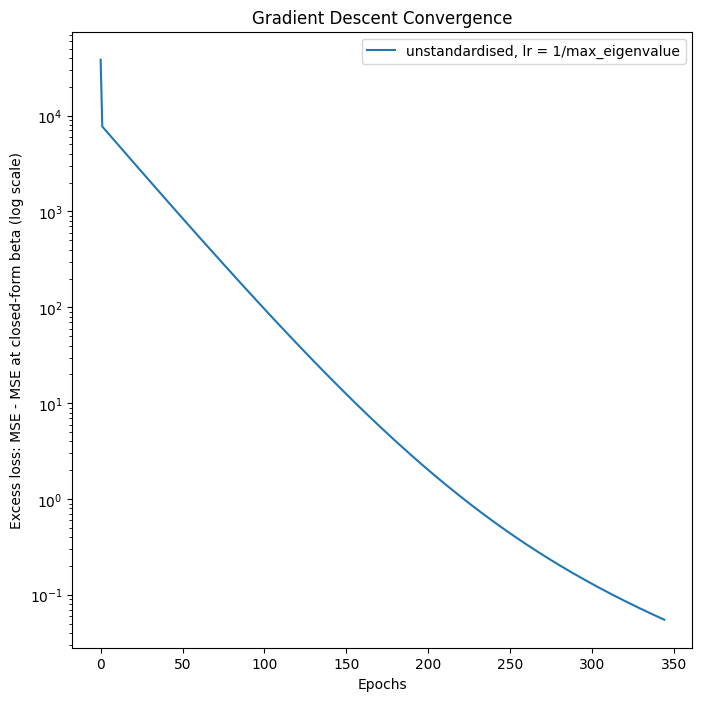

In [19]:
gd = MultipleLinearRegression().fit_gd(X_train, y_train)

mlr = MultipleLinearRegression().fit(X_train, y_train)

L_star = np.mean(mlr.residual(X_train, y_train)**2) ## SSR: SUm of Squared Residuals

excess_loss = np.array(gd.loss_history_) - L_star
excess = np.maximum(excess_loss, 1e-12)

plt.figure(figsize=(8,8))
plt.plot(excess, label="unstandardised, lr = 1/max_eigenvalue")
plt.yscale("log")
plt.xlabel("Epochs")
plt.ylabel("Excess loss: MSE - MSE at closed-form beta (log scale)")
plt.title("Gradient Descent Convergence")
plt.legend()
plt.show()

## Standardising our data to see how many epochs it will take to fit

In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)
# y_scaled = scaler.fit_transform(y.values.reshape(-1, 1)).flatten()


In [21]:
gd_model = MultipleLinearRegression()
gd_model.fit_gd(X_scaled, y_train)
print("Parameter vector beta_hat:", gd_model.beta_hat)
print("Intercept: ", gd_model.intercept_)
print("Coefficients:", gd_model.coef_)


Condition Number: 1.871710540594397
Learning Rate: 0.38749750278748835 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Converged at epoch:  9
Parameter vector beta_hat: [174.63908455  69.07632542 -49.27582951   6.83809762]
Intercept:  174.63908454619659
Coefficients: [ 69.07632542 -49.27582951   6.83809762]


In [22]:
mlr = MultipleLinearRegression()
mlr.fit(X_scaled, y_train)
print("Parameter vector beta_hat:", mlr.beta_hat)
print("Intercept: ", mlr.intercept_)
print("Coefficients:", mlr.coef_)

Condition Number: 1.871710540594397
Parameter vector beta_hat: [174.63914263  69.07492924 -49.2797021    6.83420389]
Intercept:  174.63914263108677
Coefficients: [ 69.07492924 -49.2797021    6.83420389]


## Excess Loss Plot of both Scaled and Unscaled .fit() model. For easy comparison

Condition Number: 1.871710540594397
Learning Rate: 0.38749750278748835 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Converged at epoch:  16
Condition Number: 1.871710540594397
Condition Number: 154.10384248868058
Learning Rate: 0.3000310762620823 Limit: 0.6000621525241646, Max Eigen value: 3.3329880772966427
Converged at epoch:  1180
Condition Number: 154.1038424886802


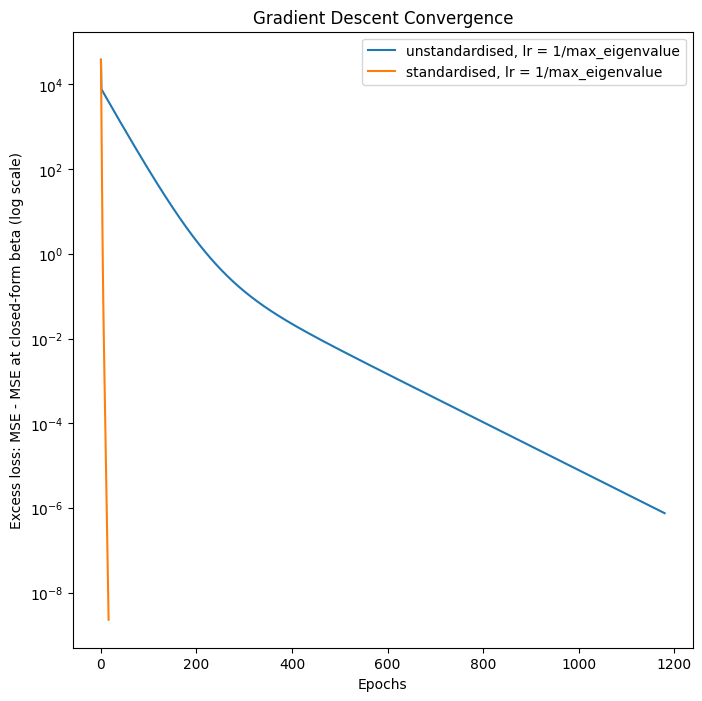

In [23]:
'''Scaled Dataset for Fit'''
gd_model = MultipleLinearRegression()
gd_model.fit_gd(X_scaled, y_train, epochs=5000, tolerance=1e-8)

mlr_sc = MultipleLinearRegression()
mlr_sc.fit(X_scaled, y_train)

L_star_scaled = np.mean(mlr_sc.residual(X_scaled, y_train)**2)

excess_loss = np.array(gd_model.loss_history_) - L_star_scaled
excess_std = np.maximum(excess_loss, 1e-12)

'''Unscaled Dataset for Fit'''
gd = MultipleLinearRegression().fit_gd(X_train, y_train, epochs=5000, tolerance=1e-8)

mlr = MultipleLinearRegression().fit(X_train, y_train)

L_star_unscaled = np.mean(mlr.residual(X_train, y_train)**2) ##  MSE

excess_loss = np.array(gd.loss_history_) - L_star_unscaled
excess_unstd = np.maximum(excess_loss, 1e-12)

'''Scaled vs Unscaled Dataset comparison'''

plt.figure(figsize=(8,8))
plt.plot(excess_unstd, label="unstandardised, lr = 1/max_eigenvalue")
plt.plot(excess_std, label="standardised, lr = 1/max_eigenvalue")
plt.yscale("log")
plt.xlabel("Epochs")
plt.ylabel("Excess loss: MSE - MSE at closed-form beta (log scale)")
plt.title("Gradient Descent Convergence")
plt.legend()
plt.show()

####

### Let us see if L* scaled == MSE of scaled == L*of unscaled.
it will be true as both are `y_train` only

In [24]:
np.allclose(L_star_scaled, L_star_unscaled)

True

Let us compare that if Loss at epoch 0 == y**2 or not

In [25]:
a = np.mean((y_train ** 2))

b = gd_model.loss_history_[0]

print(np.allclose(a,b))



True


### Visualising our dear beta hat, with X_train and y_train

Condition Number: 154.1038424886802


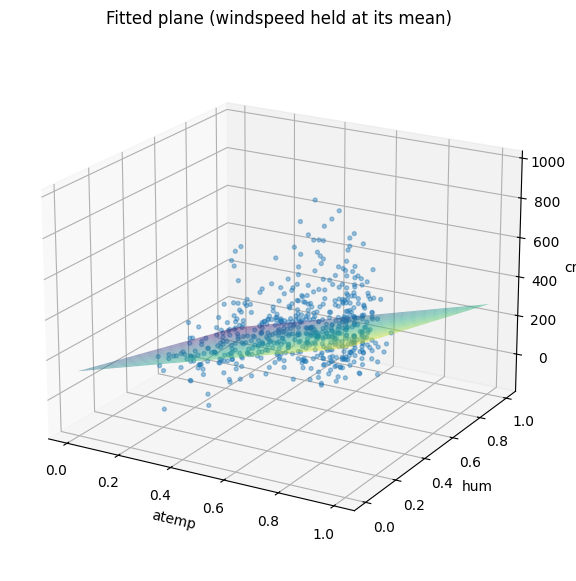

In [27]:
model = MultipleLinearRegression()
model.fit(X_train, y_train)

import numpy as np
import matplotlib.pyplot as plt

beta = model.beta_hat      # [b0, b_atemp, b_hum, b_windspeed], from the same feature space as Xdf
Xdf = X_train              # must have columns atemp, hum, windspeed (raw units if beta is from the raw fit)
y = np.asarray(y_train)

fixed_wind = Xdf['windspeed'].mean()   # the held-out feature

# grid over the two plotted features
a = np.linspace(Xdf['atemp'].min(), Xdf['atemp'].max(), 30)
h = np.linspace(Xdf['hum'].min(), Xdf['hum'].max(), 30)
A, H = np.meshgrid(a, h)

# YOUR PART: predicted cnt at every grid point (same shape as A and H).
# It's the model's formula written out column by column, using beta, A, H and fixed_wind.
Z = beta[0] + A*beta[1] + H*beta[2]

# plot
idx = np.random.default_rng(0).choice(len(Xdf), size=600, replace=False)  # 13,903 points is too many

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(Xdf['atemp'].values[idx], Xdf['hum'].values[idx], y[idx], s=8, alpha=0.4)
ax.plot_surface(A, H, Z, alpha=0.5, cmap='viridis')
ax.set_xlabel('atemp'); ax.set_ylabel('hum'); ax.set_zlabel('cnt')
ax.set_title('Fitted plane (windspeed held at its mean)')
ax.view_init(elev=20, azim=-60)
plt.show()

In [29]:
import numpy as np
import plotly.graph_objects as go

beta = model.beta_hat          # the fit made on raw X_train: [131.8, 391.1, -248.7, 55.6]
Xdf = X_train                  # DataFrame with columns atemp, hum, windspeed
y = np.asarray(y_train)

wind = Xdf['windspeed'].mean()

a = np.linspace(Xdf['atemp'].min(), Xdf['atemp'].max(), 30)
h = np.linspace(Xdf['hum'].min(), Xdf['hum'].max(), 30)
A, H = np.meshgrid(a, h)

Z = beta[0] + A*beta[1] + H*beta[2] + beta[3]*wind     # your formula

idx = np.random.default_rng(0).choice(len(Xdf), size=600, replace=False)

fig = go.Figure([
    go.Surface(x=A, y=H, z=Z, opacity=0.6, colorscale='Viridis'),
    go.Scatter3d(x=Xdf['atemp'].values[idx], y=Xdf['hum'].values[idx], z=y[idx],
                mode='markers', marker=dict(size=2, opacity=0.5)),
])
fig.update_layout(scene=dict(xaxis_title='atemp', yaxis_title='hum', zaxis_title='cnt'),
            title='Fitted plane (windspeed held at its mean)', width=900, height=700)
fig.show()

## Learning Rate Sweep: 1e-4, -3, -2, -1, 0.5, 1, 5, 10

In [20]:
features = ['atemp', 'hum', 'windspeed']

X = df[features]
y = df['cnt']

X_train, X_test, y_train, y_test = train_test_split(X, y,shuffle=False, test_size=0.2)


For learning rate: 0.0001
Condition Number: 1.871710540594397
Learning Rate: 0.0001 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Intercept:  31.65956586931908
Coefficients:  [12.87706515 -9.79445113  2.86843671]
Parameter Vector:  [31.65956587 12.87706515 -9.79445113  2.86843671]


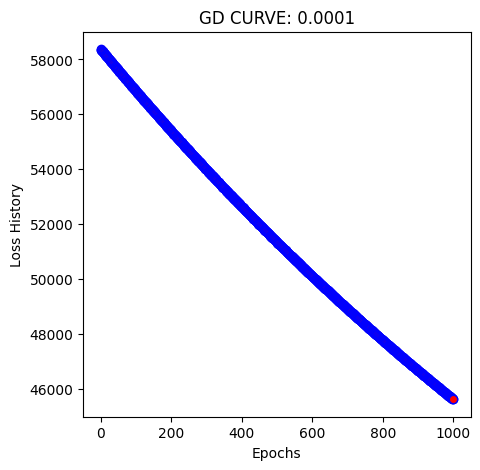

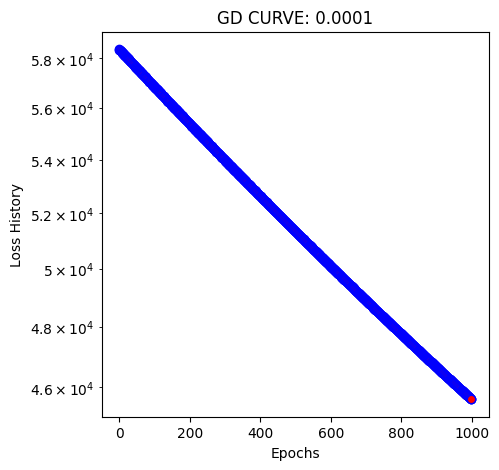


With 5000 epochs: 
Condition Number: 1.871710540594397
Learning Rate: 0.0001 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Intercept:  110.39941758376091
Coefficients:  [ 44.51586489 -32.65925653   7.81423268]
Parameter Vector:  [110.39941758  44.51586489 -32.65925653   7.81423268]


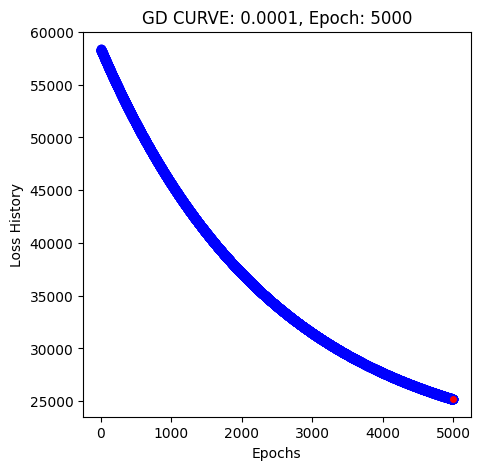

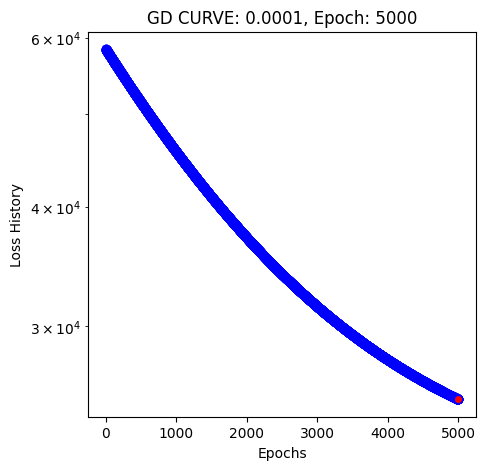

In [ ]:
'''1e-4'''


def learning_rate_sweeper(lr=None):
    gd = MultipleLinearRegression()
    gd.fit_gd(X_scaled, y_train, lr_=lr)
    print("Intercept: ", gd.intercept_)
    print("Coefficients: ", gd.coef_)
    print("Parameter Vector: ",gd.beta_hat)

    '''On Normal Scale'''
    plt.figure(figsize=(5,5))
    plt.plot(gd.loss_history_, color='blue', linestyle='--',  marker='o', markerfacecolor='red')
    plt.title(f"GD CURVE: {gd.lr_}")
    plt.xlabel("Epochs")
    plt.ylabel("Loss History")
    plt.show()

    '''On Log Scale'''
    plt.figure(figsize=(5,5))
    plt.plot(gd.loss_history_, color='blue', linestyle='--', marker='o', markerfacecolor='red')
    plt.title(f"GD CURVE: {gd.lr_}")
    plt.xlabel("Epochs")
    plt.yscale('log')
    plt.ylabel("Loss History")
    plt.show()


    return None

def learning_rate_sweeper_with_epoch(lr=None, epochs=1000):
        gd = MultipleLinearRegression()
        gd.fit_gd(X_scaled, y_train, lr_=lr, epochs=epochs)
        print("Intercept: ", gd.intercept_)
        print("Coefficients: ", gd.coef_)
        print("Parameter Vector: ",gd.beta_hat)


        '''on normal scale'''
        plt.figure(figsize=(5,5))
        plt.plot(gd.loss_history_, color='blue', linestyle='--' ,marker='o', markerfacecolor='red')
        plt.title(f"GD CURVE: {gd.lr_}, Epoch: {epochs}")
        plt.xlabel("Epochs")
        plt.ylabel("Loss History")
        plt.show()
        
        
        '''On log-scale'''
        plt.figure(figsize=(5,5))
        plt.plot(gd.loss_history_, color='blue', linestyle='--',  marker='o', markerfacecolor='red')
        plt.title(f"GD CURVE: {gd.lr_}, Epoch: {epochs}")
        plt.xlabel("Epochs")
        plt.yscale('log')
        plt.ylabel("Loss History")
        plt.show()


print("For learning rate: 0.0001")
learning_rate_sweeper(1e-4)

print("\nWith 5000 epochs: ")
learning_rate_sweeper_with_epoch(1e-4, 5000)

Condition Number: 1.871710540594397
Learning Rate: 0.001 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Intercept:  151.05159023112085
Coefficients:  [ 60.42679449 -43.35605206   8.39619983]
Parameter Vector:  [151.05159023  60.42679449 -43.35605206   8.39619983]


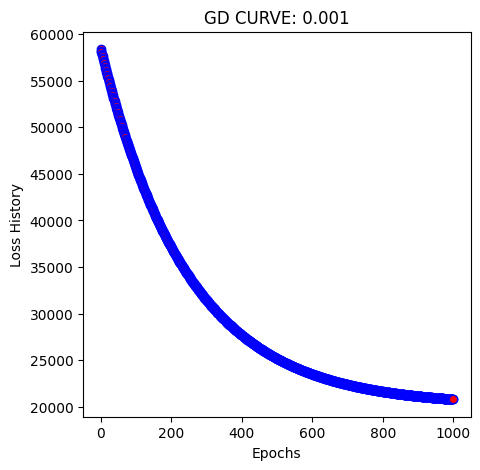

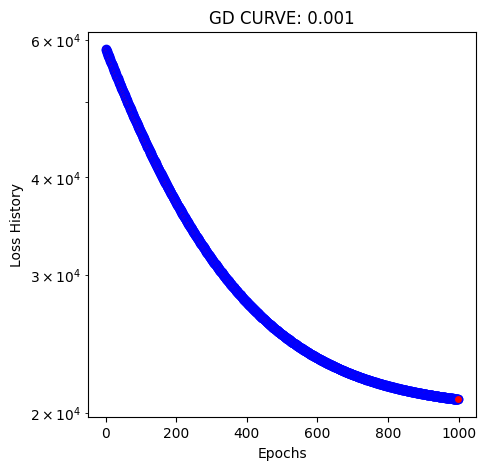


With 5000 epochs: 
Condition Number: 1.871710540594397
Learning Rate: 0.001 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Converged at epoch:  2981
Intercept:  174.1930595933687
Coefficients:  [ 68.95830472 -49.10322671   6.98162292]
Parameter Vector:  [174.19305959  68.95830472 -49.10322671   6.98162292]


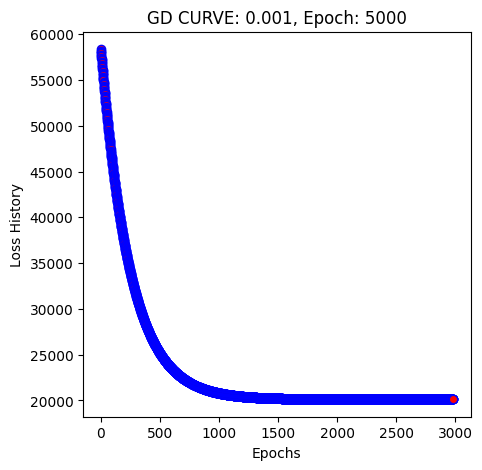

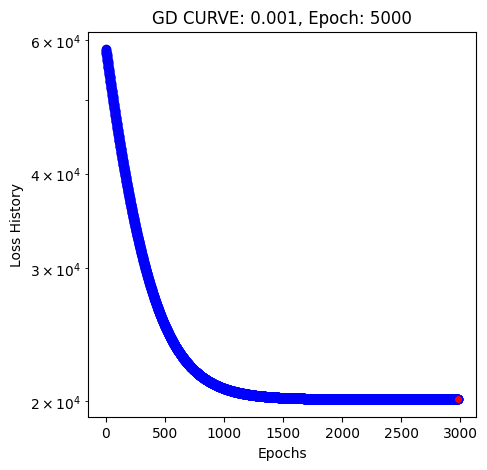

In [24]:
learning_rate_sweeper(1e-3)

print("\nWith 5000 epochs: ")
learning_rate_sweeper_with_epoch(1e-3, 5000)

Condition Number: 1.871710540594397
Learning Rate: 0.01 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Converged at epoch:  355
Intercept:  174.50773380455058
Coefficients:  [ 69.04860607 -49.21035555   6.89738967]
Parameter Vector:  [174.5077338   69.04860607 -49.21035555   6.89738967]


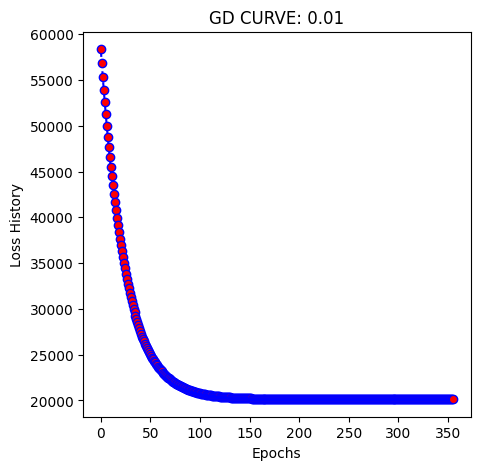

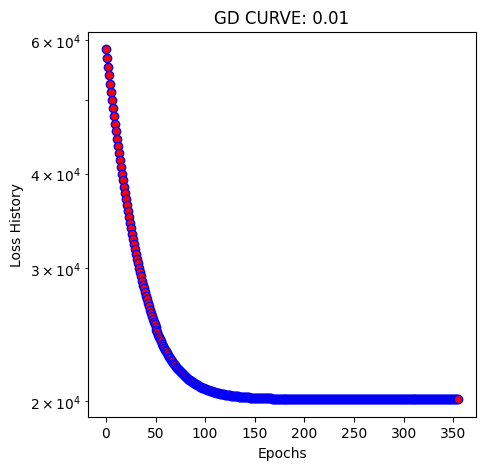


With 5000 epochs: 
Condition Number: 1.871710540594397
Learning Rate: 0.01 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Converged at epoch:  355
Intercept:  174.50773380455058
Coefficients:  [ 69.04860607 -49.21035555   6.89738967]
Parameter Vector:  [174.5077338   69.04860607 -49.21035555   6.89738967]


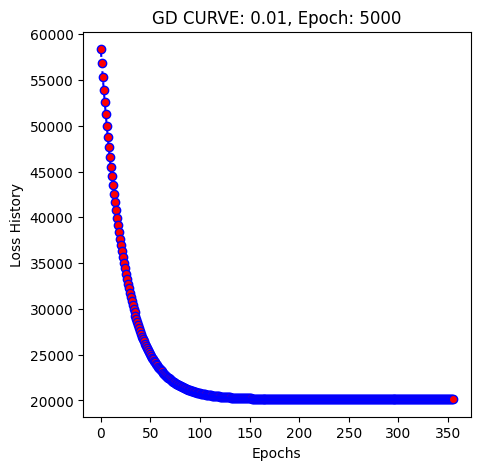

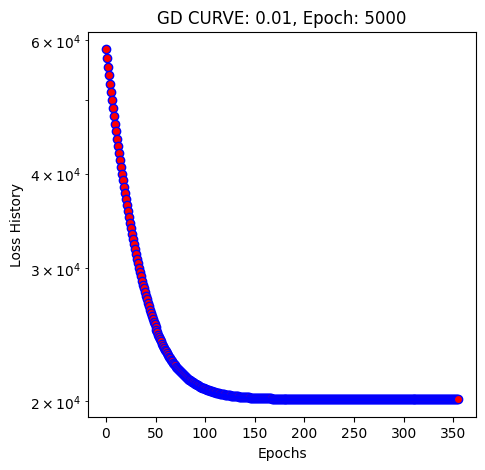

In [66]:
learning_rate_sweeper(1e-2)

print("\nWith 5000 epochs: ")
learning_rate_sweeper_with_epoch(1e-2, 5000)

Condition Number: 1.871710540594397
Learning Rate: 0.1 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Converged at epoch:  39
Intercept:  174.61592910733228
Coefficients:  [ 69.07479166 -49.25661975   6.85678552]
Parameter Vector:  [174.61592911  69.07479166 -49.25661975   6.85678552]


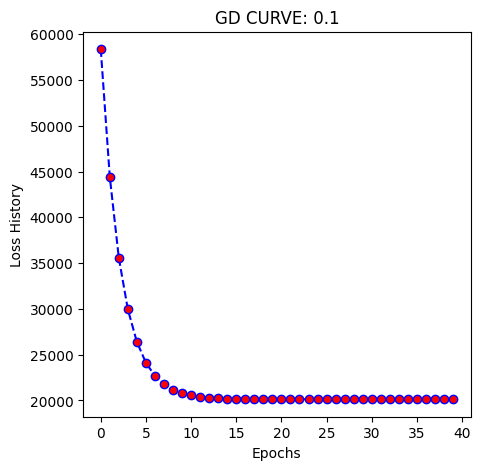

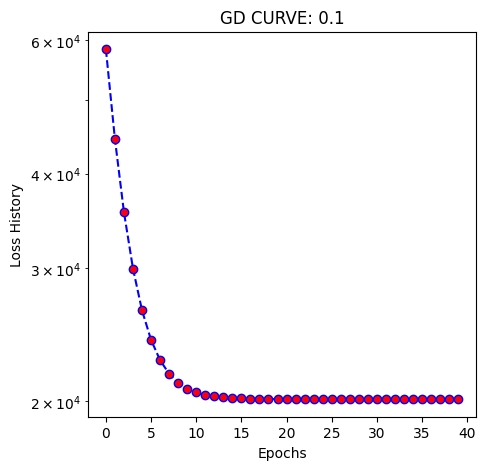


With 5000 epochs: 
Condition Number: 1.871710540594397
Learning Rate: 0.1 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Converged at epoch:  39
Intercept:  174.61592910733228
Coefficients:  [ 69.07479166 -49.25661975   6.85678552]
Parameter Vector:  [174.61592911  69.07479166 -49.25661975   6.85678552]


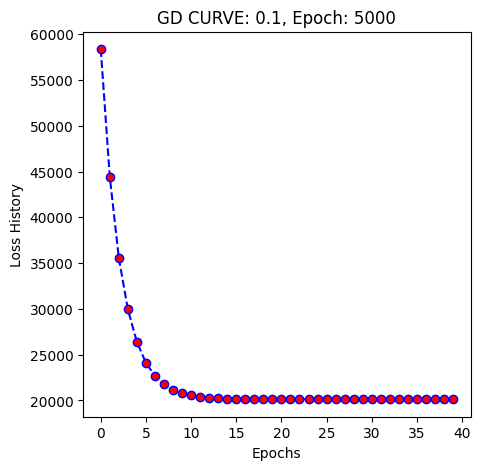

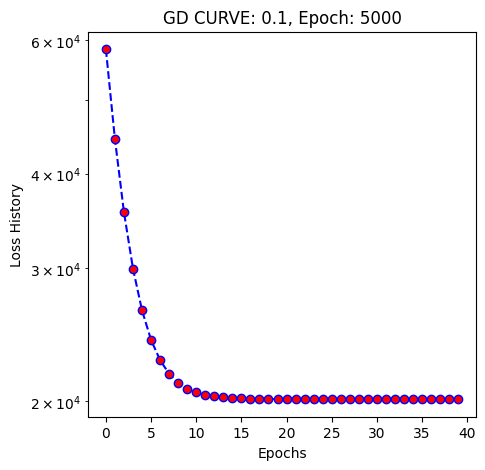

In [26]:
learning_rate_sweeper(1e-1)

print("\nWith 5000 epochs: ")
learning_rate_sweeper_with_epoch(1e-1, 5000)

Condition Number: 1.871710540594397
Learning Rate: 0.5 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Converged at epoch:  7
Intercept:  174.6391426310868
Coefficients:  [ 69.07522791 -49.27765302   6.83354707]
Parameter Vector:  [174.63914263  69.07522791 -49.27765302   6.83354707]


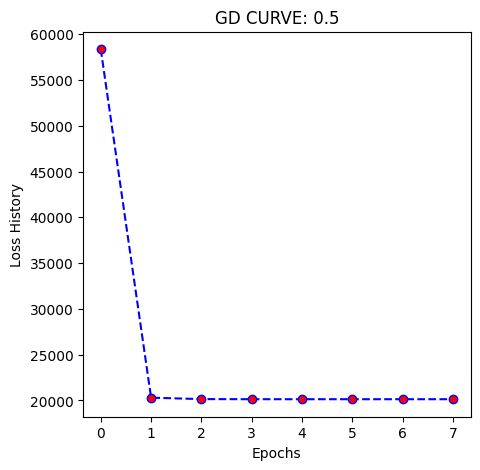

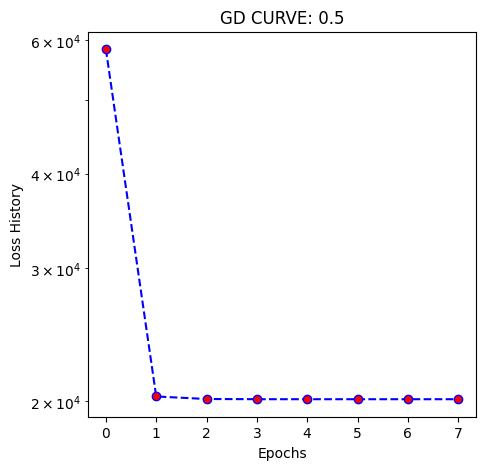


With 5000 epochs: 
Condition Number: 1.871710540594397
Learning Rate: 0.5 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Converged at epoch:  7
Intercept:  174.6391426310868
Coefficients:  [ 69.07522791 -49.27765302   6.83354707]
Parameter Vector:  [174.63914263  69.07522791 -49.27765302   6.83354707]


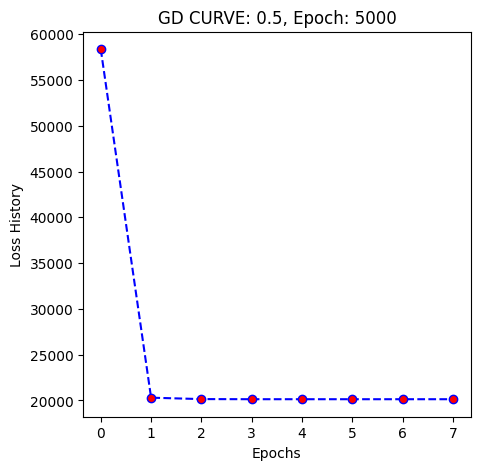

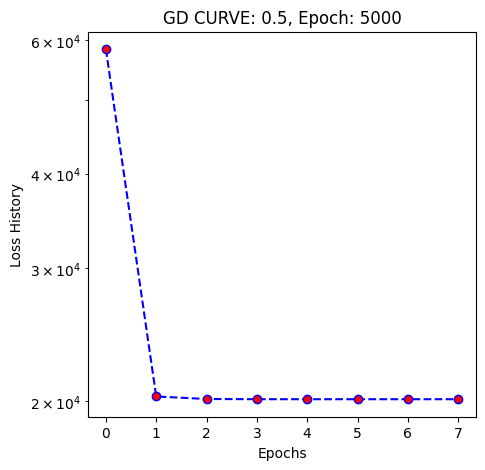

In [67]:
learning_rate_sweeper(0.5)

print("\nWith 5000 epochs: ")
learning_rate_sweeper_with_epoch(0.5, 5000)

Condition Number: 1.871710540594397
Learning Rate: 1 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Diverged at epoch: 757
Intercept:  -4.6078085072123776e+136
Coefficients:  [ 4.63183182e+150  1.40377725e+152 -1.41276600e+152]
Parameter Vector:  [-4.60780851e+136  4.63183182e+150  1.40377725e+152 -1.41276600e+152]


c:\Users\Sarthak\anaconda3\Lib\site-packages\numpy\_core\_methods.py:134: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


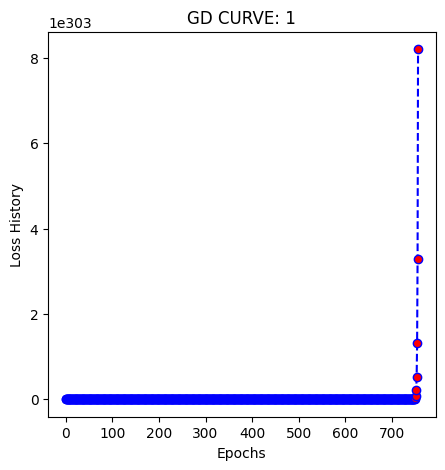

C:\Users\Sarthak\AppData\Roaming\Python\Python313\site-packages\matplotlib\scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


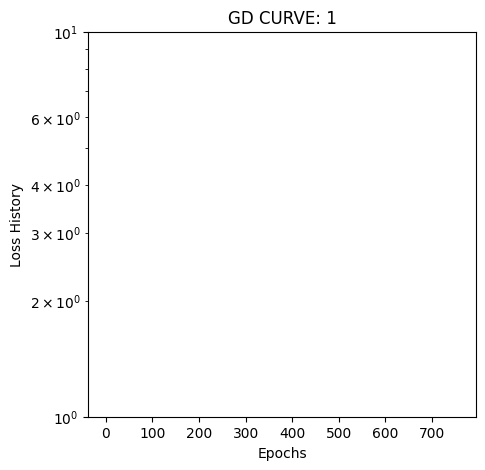


With 5000 epochs: 
Condition Number: 1.871710540594397
Learning Rate: 1 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Diverged at epoch: 757
Intercept:  -4.6078085072123776e+136
Coefficients:  [ 4.63183182e+150  1.40377725e+152 -1.41276600e+152]
Parameter Vector:  [-4.60780851e+136  4.63183182e+150  1.40377725e+152 -1.41276600e+152]


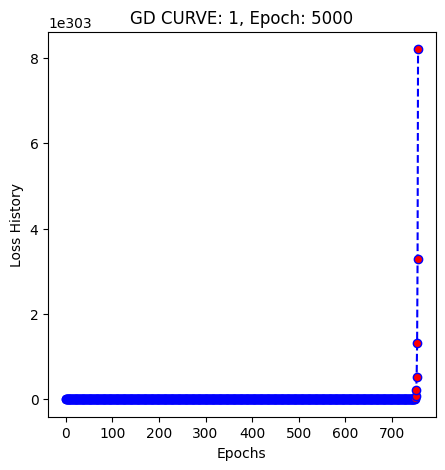

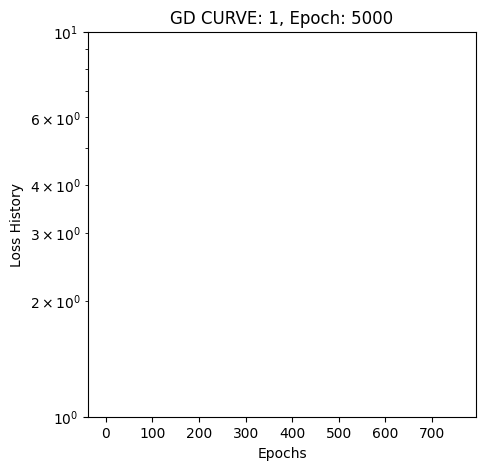

In [68]:
learning_rate_sweeper(1)

print("\nWith 5000 epochs: ")
learning_rate_sweeper_with_epoch(1, 5000)

Condition Number: 1.871710540594397
Learning Rate: 10 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Diverged at epoch: 108
Intercept:  4.2301523587311226e+141
Coefficients:  [-8.98852004e+151 -2.72416626e+153  2.74160979e+153]
Parameter Vector:  [ 4.23015236e+141 -8.98852004e+151 -2.72416626e+153  2.74160979e+153]


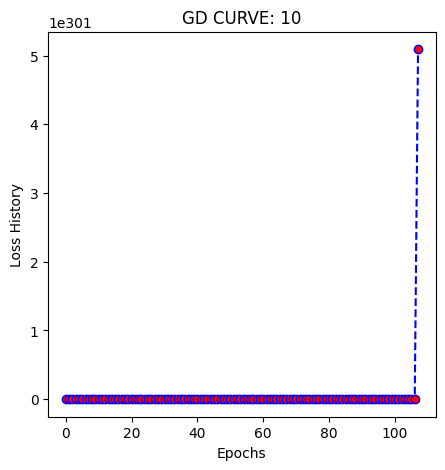

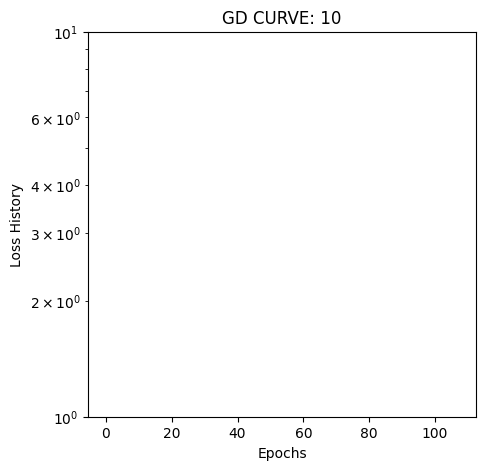


With 5000 epochs: 
Condition Number: 1.871710540594397
Learning Rate: 10 Limit: 0.7749950055749767, Max Eigen value: 2.5806617921572017
Diverged at epoch: 108
Intercept:  4.2301523587311226e+141
Coefficients:  [-8.98852004e+151 -2.72416626e+153  2.74160979e+153]
Parameter Vector:  [ 4.23015236e+141 -8.98852004e+151 -2.72416626e+153  2.74160979e+153]


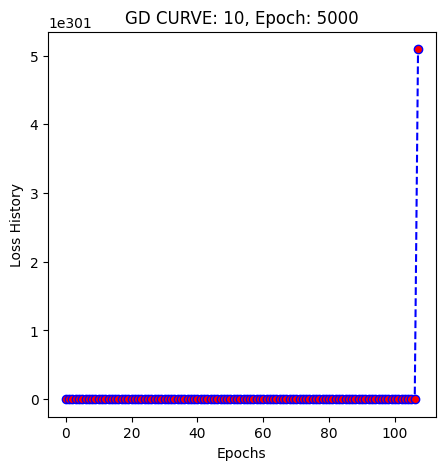

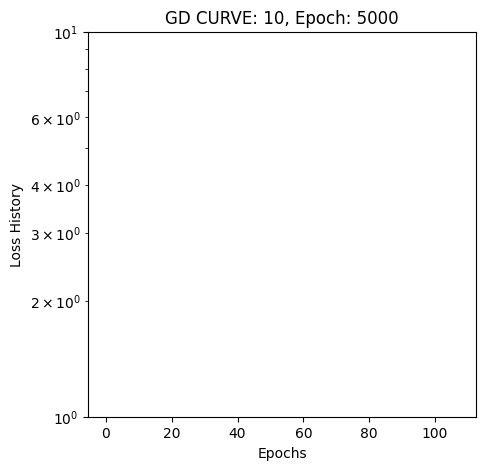

In [69]:
learning_rate_sweeper(10)

print("\nWith 5000 epochs: ")
learning_rate_sweeper_with_epoch(10, 5000)